<a href="https://colab.research.google.com/github/AnushkSingh/Pet_Segmentation_Project/blob/main/Pet_Segmentation_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Step 1: Dataset and data contract**

Import required libraries

In [ ]:

import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import random
import json

from torchvision.datasets import OxfordIIITPet
from torch.utils.data import random_split

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True


Download the dataset

In [ ]:

trainval_dataset = OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="segmentation",
    download=True
)

test_dataset = OxfordIIITPet(
    root="./data",
    split="test",
    target_types="segmentation",
    download=False
)

print("Train + Validation:", len(trainval_dataset))
print("Test:", len(test_dataset))


Train + Validation: 3680
Test: 3669


Split training and validation data

In [ ]:

train_size = int(0.8 * len(trainval_dataset))
val_size = len(trainval_dataset) - train_size

train_dataset, val_dataset = random_split(
    trainval_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

# Save the indices to reproduce our split
with open("split_indices.json", "w") as f:
    json.dump({
        "seed": SEED,
        "train_indices": train_dataset.indices,
        "val_indices": val_dataset.indices
    }, f)


Training: 2944
Validation: 736
Testing: 3669


Visualize an image and its ground-truth mask. Here we wanted to understand what our dataset contains and what our segmentation model will learn to predict.

Image shape: (500, 394, 3)
Mask shape: (500, 394)
Unique mask values: [1 2 3]


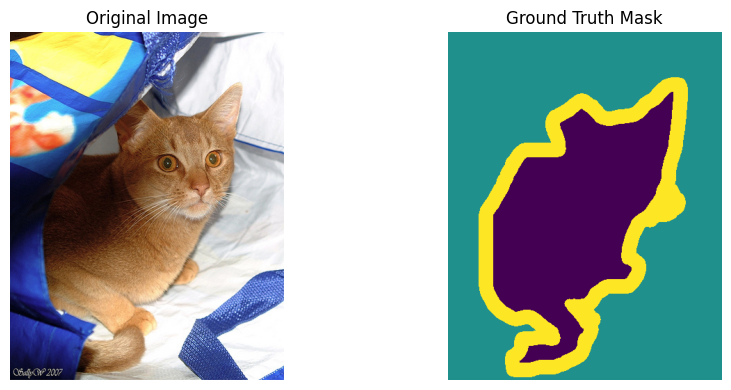

In [ ]:

image, mask = trainval_dataset[0]

image_np = np.array(image)
mask_np = np.array(mask)

print("Image shape:", image_np.shape)
print("Mask shape:", mask_np.shape)
print("Unique mask values:", np.unique(mask_np))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(image_np)
ax[0].set_title("Original Image")

ax[1].imshow(mask_np, cmap="viridis", vmin=1, vmax=3)
ax[1].set_title("Ground Truth Mask")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


For this experiment, we have selected the **Oxford-IIIT Pet Dataset**, a publicly available annotated dataset, to perform **binary semantic segmentation**. A fixed random seed of **42** is used to ensure reproducibility of our train-validation allocation.Without a fixed seed, different runs can create different splits, which makes the results harder to compare.The original training and validation dataset is divided into **80% training data and 20% validation data**, this ratio is chosen as it ensures a good practical balance between images available for training and testing while the official test dataset is kept separate for final evaluation. In the segmentation masks, pixels belonging to the pet are assigned class ID **1**, background pixels are assigned class ID **0**, and boundary pixels are assigned the ignore label **255**, so they are excluded from training loss calculations and evaluation metrics. All images and their corresponding segmentation masks will be resized to a resolution of **160 × 160 pixels**. Bilinear interpolation will be used for resizing input images, whereas nearest-neighbor interpolation will be used for segmentation masks to preserve their discrete class labels. Additionally, **random horizontal flipping** will be applied as a data augmentation technique only during training to improve the model's ability to generalize to unseen images. These preprocessing steps and experimental settings will be kept consistent across the baseline and modified models to ensure a fair and reproducible comparison.

**Step 2: Data Preprocessing and DataLoader Creation**

Create a custom Dataset class. Here we do image resizing, converting masks into binary labels and do data augmentation.

In [ ]:

import torch
import numpy as np
import random

from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

IMAGE_SIZE = 160

class PetSegmentationDataset(Dataset):

    def __init__(self, dataset, augment=False):
        self.dataset = dataset
        self.augment = augment

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):

        # Get the original image and mask
        image, mask = self.dataset[idx]
        image = image.convert("RGB")

        # Resize the image using bilinear interpolation
        image = TF.resize(
            image,
            [IMAGE_SIZE, IMAGE_SIZE],
            interpolation=InterpolationMode.BILINEAR
        )

        # Resize the mask using nearest-neighbor interpolation
        mask = TF.resize(
            mask,
            [IMAGE_SIZE, IMAGE_SIZE],
            interpolation=InterpolationMode.NEAREST
        )

        # Apply augmentation only during training
        if self.augment and random.random() < 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)

        # Convert image to tensor with values in [0, 1]
        image = TF.to_tensor(image)

        # Convert original mask values to binary labels
        mask_np = np.array(mask)

        binary_mask = np.full(
            mask_np.shape, 255, dtype=np.uint8
        )

        binary_mask[mask_np == 1] = 1  # Pet
        binary_mask[mask_np == 2] = 0  # Background
        # Original boundary (3) remains 255

        mask = torch.from_numpy(
            binary_mask.astype(np.int64)
        )

        return image, mask


Apply preprocessing to our dataset splits

In [ ]:

train_processed = PetSegmentationDataset(
    train_dataset,
    augment=True
)

val_processed = PetSegmentationDataset(
    val_dataset,
    augment=False
)

test_processed = PetSegmentationDataset(
    test_dataset,
    augment=False
)

print("Training:", len(train_processed))
print("Validation:", len(val_processed))
print("Testing:", len(test_processed))


Training: 2944
Validation: 736
Testing: 3669


Create DataLoaders

In [ ]:

BATCH_SIZE = 8

train_loader = DataLoader(
    train_processed,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_processed,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_processed,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 368
Validation batches: 92
Testing batches: 459


Verify that our DataLoader is working

In [ ]:

images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Unique mask values:", torch.unique(masks))

assert images.shape == (8, 3, 160, 160)
assert masks.shape == (8, 160, 160)
assert set(torch.unique(masks).tolist()).issubset(
    {0, 1, 255}
)

print("DataLoader verification successful!")


Image batch shape: torch.Size([8, 3, 160, 160])
Mask batch shape: torch.Size([8, 160, 160])
Unique mask values: tensor([  0,   1, 255])
DataLoader verification successful!


Visualize the processed image and mask

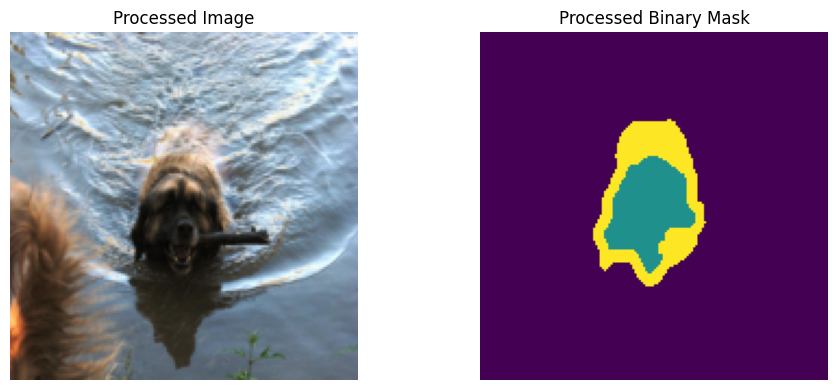

In [ ]:

import matplotlib.pyplot as plt

image, mask = train_processed[0]

image_np = image.permute(1, 2, 0).numpy()
mask_np = mask.numpy().copy()

# Map 255 to 2 for visualization only
mask_np[mask_np == 255] = 2

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(image_np)
ax[0].set_title("Processed Image")

ax[1].imshow(
    mask_np,
    cmap="viridis",
    vmin=0,
    vmax=2
)
ax[1].set_title("Processed Binary Mask")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# ***Implementing the Baseline U-Net Model***

U-Net consists of three major components:
1. Encoder (Contracting path): Extracts image features while reducing spatial resolution.
2. Bottleneck: Processes the deepest features, capturing broader context.
3. Decoder (Expanding path): Upsamples features to recover the original resolution.

Implement the Double Convolution Block

In [ ]:

import torch
import torch.nn as nn

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels, dilation=1):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=dilation,
                dilation=dilation
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=dilation,
                dilation=dilation
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


Implement the complete U-Net

In [ ]:

class UNetSmall(nn.Module):

    def __init__(self, num_classes=2, bottleneck_dilation=1):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(3, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(
            64, 128,
            dilation=bottleneck_dilation
        )

        # Decoder
        self.up3 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, 2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, 2)
        self.dec1 = DoubleConv(32, 16)

        # Output layer
        self.final_conv = nn.Conv2d(
            16, num_classes, kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # Bottleneck
        b = self.bottleneck(self.pool(e3))

        # Decoder
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        # Final prediction
        output = self.final_conv(d1)

        return output


Initialize our baseline model

In [ ]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.manual_seed(SEED)

baseline_model = UNetSmall(
    num_classes=2,
    bottleneck_dilation=1
).to(device)

print("Device:", device)
print("Baseline U-Net created successfully!")


Device: cuda
Baseline U-Net created successfully!


Check whether our model works

In [ ]:

images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

baseline_model.eval()

with torch.no_grad():
    outputs = baseline_model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Target mask shape:", masks.shape)


Input shape: torch.Size([8, 3, 160, 160])
Output shape: torch.Size([8, 2, 160, 160])
Target mask shape: torch.Size([8, 160, 160])


Calculate the number of trainable parameters

In [ ]:

total_params = sum(
    p.numel()
    for p in baseline_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)
print("Parameters (millions):", round(total_params / 1e6, 3))


Trainable parameters: 483458
Parameters (millions): 0.483


Check the training loss

In [ ]:

criterion = nn.CrossEntropyLoss(
    ignore_index=255
)

loss = criterion(outputs, masks)

print("Initial loss:", loss.item())
print("Finite loss:", torch.isfinite(loss).item())


Initial loss: 0.6603863835334778
Finite loss: True


# **Step 4: Training the Baseline U-Net Mode**

Define training hyperparameters

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
import json

SEED = 42
LEARNING_RATE = 0.001
NUM_EPOCHS = 12
BATCH_SIZE = 8

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Learning rate:", LEARNING_RATE)
print("Number of epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)


Device: cuda
Learning rate: 0.001
Number of epochs: 12
Batch size: 8


Set up reproducibility. We want the baseline and modified models to start under comparable experimental conditions.

In [ ]:

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def make_loaders(seed):

    generator = torch.Generator().manual_seed(seed)

    train_dl = DataLoader(
        train_processed,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    val_dl = DataLoader(
        val_processed,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    return train_dl, val_dl


set_seed(SEED)

train_loader, val_loader = make_loaders(SEED)

# Recreate the baseline model with a fixed initialization seed
baseline_model = UNetSmall(
    num_classes=2,
    bottleneck_dilation=1
).to(device)


Define loss function and optimizer

In [ ]:

criterion = nn.CrossEntropyLoss(
    ignore_index=255
)

optimizer = optim.Adam(
    baseline_model.parameters(),
    lr=LEARNING_RATE
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)


Loss function: CrossEntropyLoss()
Optimizer: Adam


The training function

In [ ]:

def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    total_loss = 0.0
    total_valid_pixels = 0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        # Clear old gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, masks)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Accumulate loss using valid pixel counts
        valid_pixels = (masks != 255).sum().item()

        total_loss += loss.item() * valid_pixels
        total_valid_pixels += valid_pixels

    return total_loss / total_valid_pixels


Write the validation function

In [ ]:

def validate_one_epoch(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    total_valid_pixels = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = criterion(outputs, masks)

            valid_pixels = (masks != 255).sum().item()

            total_loss += loss.item() * valid_pixels
            total_valid_pixels += valid_pixels

    return total_loss / total_valid_pixels


Train our baseline U-Net

In [ ]:

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_epoch = 0

for epoch in range(NUM_EPOCHS):

    train_loss = train_one_epoch(
        baseline_model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss = validate_one_epoch(
        baseline_model,
        val_loader,
        criterion
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # Save the checkpoint with lowest validation loss
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": baseline_model.state_dict(),
            "validation_loss": best_val_loss,
            "seed": SEED,
            "learning_rate": LEARNING_RATE,
            "batch_size": BATCH_SIZE,
            "num_epochs": NUM_EPOCHS,
            "bottleneck_dilation": 1,
            "image_size": IMAGE_SIZE
        }, "baseline_unet_best.pth")

print("\nTraining completed!")
print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)


Epoch [1/12] Train Loss: 0.4111 | Val Loss: 0.3792
Epoch [2/12] Train Loss: 0.3125 | Val Loss: 0.2864
Epoch [3/12] Train Loss: 0.2729 | Val Loss: 0.2470
Epoch [4/12] Train Loss: 0.2479 | Val Loss: 0.2277
Epoch [5/12] Train Loss: 0.2245 | Val Loss: 0.2182
Epoch [6/12] Train Loss: 0.2208 | Val Loss: 0.2264
Epoch [7/12] Train Loss: 0.2075 | Val Loss: 0.1856
Epoch [8/12] Train Loss: 0.1972 | Val Loss: 0.1923
Epoch [9/12] Train Loss: 0.1890 | Val Loss: 0.1706
Epoch [10/12] Train Loss: 0.1810 | Val Loss: 0.1839
Epoch [11/12] Train Loss: 0.1730 | Val Loss: 0.1707
Epoch [12/12] Train Loss: 0.1739 | Val Loss: 0.1523

Training completed!
Best epoch: 12
Best validation loss: 0.15232408078250317


Plot training and validation loss

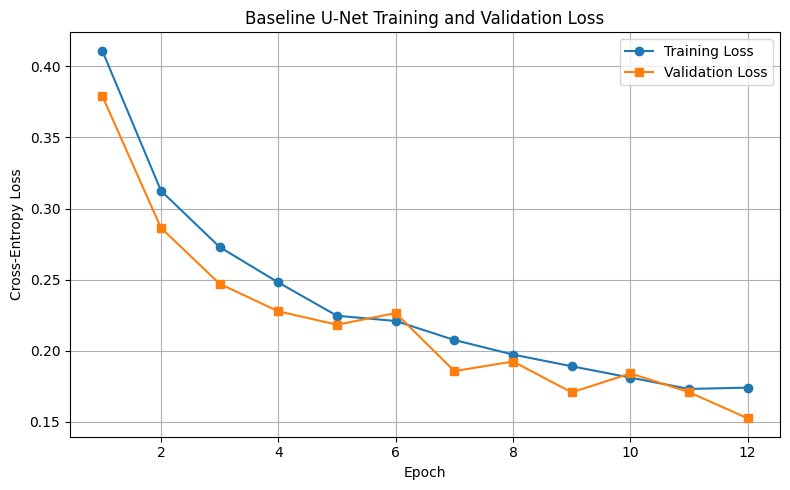

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    train_losses,
    label="Training Loss",
    marker="o"
)

plt.plot(
    range(1, NUM_EPOCHS + 1),
    val_losses,
    label="Validation Loss",
    marker="s"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Baseline U-Net Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Load the best saved baseline model

In [ ]:

checkpoint = torch.load(
    "baseline_unet_best.pth",
    map_location=device,
    weights_only=True
)

baseline_model.load_state_dict(
    checkpoint["model_state_dict"]
)

baseline_model.eval()

print("Best model loaded successfully!")
print("Selected epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["validation_loss"])


Best model loaded successfully!
Selected epoch: 12
Validation loss: 0.15232408078250317


Saving our model offline

In [ ]:

import json

history = {
    "training_loss": train_losses,
    "validation_loss": val_losses,
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss
}

with open("baseline_history.json", "w") as f:
    json.dump(history, f, indent=4)

# For Google Colab
from google.colab import files

files.download("baseline_unet_best.pth")
files.download("baseline_history.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Step 5: Modify the U-Net Architecture (Controlled Experiment)**

What are we changing?
We will introduce dilated convolution in the bottleneck of our U-Net.
In standard convolution, a 3 × 3 kernel processes nine neighboring positions.

When dilation is 2, the kernel samples positions farther apart. It covers a 5 × 5 spatial extent while still using nine kernel weights per input-output channel pair.

This allows the network to incorporate information from a larger spatial region without increasing the convolution's parameter count.

Our research question is:

Does using dilation = 2 in the bottleneck improve pet segmentation compared with the original U-Net using dilation = 1? Rest of the things are kept as it is.

Create the modified U-Net

In [ ]:

from pathlib import Path

# Ensure the baseline experiment is completed
assert Path("baseline_unet_best.pth").exists(), (
    "Run Step 4 first or upload your baseline checkpoint."
)

# Reset randomness and recreate the same data order
set_seed(SEED)

modified_train_loader, modified_val_loader = make_loaders(SEED)

# Create the modified architecture
modified_model = UNetSmall(
    num_classes=2,
    bottleneck_dilation=2
).to(device)

print("Modified U-Net created successfully!")
print("Bottleneck dilation:", 2)


Modified U-Net created successfully!
Bottleneck dilation: 2


Compare the number of parameters

In [ ]:

def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

baseline_params = count_parameters(baseline_model)
modified_params = count_parameters(modified_model)

print("Baseline parameters:", baseline_params)
print("Modified parameters:", modified_params)
print("Difference:", modified_params - baseline_params)

assert baseline_params == modified_params


Baseline parameters: 483458
Modified parameters: 483458
Difference: 0


Configure the optimizer for the modified model

In [ ]:

modified_optimizer = torch.optim.Adam(
    modified_model.parameters(),
    lr=LEARNING_RATE
)

modified_criterion = nn.CrossEntropyLoss(
    ignore_index=255
)

print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)
print("Loss: CrossEntropyLoss")


Optimizer: Adam
Learning rate: 0.001
Loss: CrossEntropyLoss


Train the modified U-Net

In [ ]:

modified_train_losses = []
modified_val_losses = []

modified_best_val_loss = float("inf")
modified_best_epoch = 0

for epoch in range(NUM_EPOCHS):

    train_loss = train_one_epoch(
        modified_model,
        modified_train_loader,
        modified_optimizer,
        modified_criterion
    )

    val_loss = validate_one_epoch(
        modified_model,
        modified_val_loader,
        modified_criterion
    )

    modified_train_losses.append(train_loss)
    modified_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # Same checkpoint-selection rule as baseline
    if val_loss < modified_best_val_loss:

        modified_best_val_loss = val_loss
        modified_best_epoch = epoch + 1

        torch.save({
            "epoch": modified_best_epoch,
            "model_state_dict": modified_model.state_dict(),
            "validation_loss": modified_best_val_loss,
            "seed": SEED,
            "learning_rate": LEARNING_RATE,
            "batch_size": BATCH_SIZE,
            "num_epochs": NUM_EPOCHS,
            "bottleneck_dilation": 2,
            "image_size": IMAGE_SIZE
        }, "modified_unet_best.pth")

print("\nModified U-Net training completed!")
print("Best epoch:", modified_best_epoch)
print("Best validation loss:", modified_best_val_loss)


Epoch [1/12] Train Loss: 0.3862 | Val Loss: 0.3815
Epoch [2/12] Train Loss: 0.2917 | Val Loss: 0.2409
Epoch [3/12] Train Loss: 0.2519 | Val Loss: 0.2243
Epoch [4/12] Train Loss: 0.2282 | Val Loss: 0.2491
Epoch [5/12] Train Loss: 0.2088 | Val Loss: 0.2256
Epoch [6/12] Train Loss: 0.2006 | Val Loss: 0.1964
Epoch [7/12] Train Loss: 0.1848 | Val Loss: 0.1716
Epoch [8/12] Train Loss: 0.1762 | Val Loss: 0.1794
Epoch [9/12] Train Loss: 0.1642 | Val Loss: 0.1619
Epoch [10/12] Train Loss: 0.1600 | Val Loss: 0.1607
Epoch [11/12] Train Loss: 0.1476 | Val Loss: 0.1625
Epoch [12/12] Train Loss: 0.1525 | Val Loss: 0.1876

Modified U-Net training completed!
Best epoch: 10
Best validation loss: 0.16065285949480967


Compare the loss curves of both models

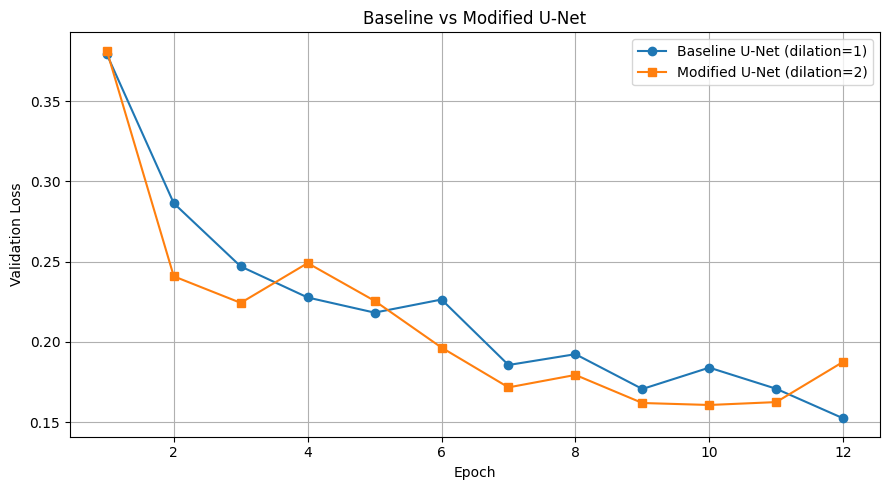

In [ ]:

import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    val_losses,
    label="Baseline U-Net (dilation=1)",
    marker="o"
)

plt.plot(
    epochs,
    modified_val_losses,
    label="Modified U-Net (dilation=2)",
    marker="s"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Baseline vs Modified U-Net")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

import json

modified_history = {
    "training_loss": modified_train_losses,
    "validation_loss": modified_val_losses,
    "best_epoch": modified_best_epoch,
    "best_validation_loss": modified_best_val_loss
}

with open("modified_history.json", "w") as f:
    json.dump(modified_history, f, indent=4)

# Load the best modified checkpoint
checkpoint = torch.load(
    "modified_unet_best.pth",
    map_location=device,
    weights_only=True
)

modified_model.load_state_dict(
    checkpoint["model_state_dict"]
)

modified_model.eval()

print("Best modified U-Net loaded successfully!")


Best modified U-Net loaded successfully!


In [ ]:

from google.colab import files

files.download("modified_unet_best.pth")
files.download("modified_history.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Step 6: Evaluate and Compare Both U-Net Models**

Load both trained models

In [ ]:

import torch
import numpy as np

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Recreate both model architectures
baseline_model = UNetSmall(
    num_classes=2,
    bottleneck_dilation=1
).to(device)

modified_model = UNetSmall(
    num_classes=2,
    bottleneck_dilation=2
).to(device)

# Load best baseline checkpoint
baseline_checkpoint = torch.load(
    "baseline_unet_best.pth",
    map_location=device,
    weights_only=True
)

baseline_model.load_state_dict(
    baseline_checkpoint["model_state_dict"]
)

# Load best modified checkpoint
modified_checkpoint = torch.load(
    "modified_unet_best.pth",
    map_location=device,
    weights_only=True
)

modified_model.load_state_dict(
    modified_checkpoint["model_state_dict"]
)

baseline_model.eval()
modified_model.eval()

print("Both trained models loaded successfully!")


Both trained models loaded successfully!


IoU evaluation function

In [ ]:

@torch.inference_mode()
def evaluate_iou(model, loader):

    model.eval()

    # Rows = actual class, columns = predicted class
    confusion = torch.zeros(
        (2, 2), dtype=torch.int64
    )

    per_image_pet_iou = []
    image_index = 0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        # Exclude ignored boundary pixels
        valid = masks != 255

        actual = masks[valid].long()
        predicted = predictions[valid].long()

        counts = torch.bincount(
            actual * 2 + predicted,
            minlength=4
        ).reshape(2, 2)

        confusion += counts.cpu()

        # Also record IoU for individual images
        for i in range(images.size(0)):

            gt = masks[i]
            pred = predictions[i]
            valid_i = valid[i]

            intersection = (
                (gt == 1) & (pred == 1) & valid_i
            ).sum().item()

            union = (
                ((gt == 1) | (pred == 1)) & valid_i
            ).sum().item()

            if union > 0:
                per_image_pet_iou.append(
                    (image_index, intersection / union)
                )

            image_index += 1

    # Compute dataset-level IoU
    intersection = confusion.diag().float()

    union = (
        confusion.sum(dim=0).float()
        + confusion.sum(dim=1).float()
        - intersection
    )

    iou = torch.where(
        union > 0,
        intersection / union,
        torch.nan
    )

    return {
        "background_iou": iou[0].item(),
        "pet_iou": iou[1].item(),
        "miou": torch.nanmean(iou).item(),
        "confusion_matrix": confusion.tolist(),
        "per_image_pet_iou": per_image_pet_iou
    }


Evaluate both models

In [ ]:

baseline_results = evaluate_iou(
    baseline_model,
    test_loader
)

modified_results = evaluate_iou(
    modified_model,
    test_loader
)

print("BASELINE U-NET")
print(
    "Background IoU:",
    round(baseline_results["background_iou"], 4)
)
print(
    "Pet IoU:",
    round(baseline_results["pet_iou"], 4)
)
print(
    "mIoU:",
    round(baseline_results["miou"], 4)
)

print("\nMODIFIED U-NET")
print(
    "Background IoU:",
    round(modified_results["background_iou"], 4)
)
print(
    "Pet IoU:",
    round(modified_results["pet_iou"], 4)
)
print(
    "mIoU:",
    round(modified_results["miou"], 4)
)


BASELINE U-NET
Background IoU: 0.9121
Pet IoU: 0.836
mIoU: 0.8741

MODIFIED U-NET
Background IoU: 0.9108
Pet IoU: 0.8415
mIoU: 0.8762


Compare the trainable parameters

In [ ]:

def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

baseline_params = count_parameters(baseline_model)
modified_params = count_parameters(modified_model)

print("Baseline parameters:", baseline_params)
print("Modified parameters:", modified_params)
print("Parameter difference:", modified_params - baseline_params)


Baseline parameters: 483458
Modified parameters: 483458
Parameter difference: 0


Inference latency

In [ ]:

import time

def measure_latency(model, input_tensor, runs=50):

    model.eval()
    input_tensor = input_tensor.to(device)

    # Warm-up runs
    with torch.inference_mode():
        for _ in range(10):
            model(input_tensor)

        if device.type == "cuda":
            torch.cuda.synchronize()

        times = []

        for _ in range(runs):

            start = time.perf_counter()

            model(input_tensor)

            if device.type == "cuda":
                torch.cuda.synchronize()

            end = time.perf_counter()

            times.append((end - start) * 1000)

    return {
        "median_ms": float(np.median(times)),
        "p95_ms": float(np.percentile(times, 95))
    }


sample_image, _ = test_processed[0]
sample_input = sample_image.unsqueeze(0)

baseline_latency = measure_latency(
    baseline_model, sample_input
)

modified_latency = measure_latency(
    modified_model, sample_input
)

print("Baseline latency:", baseline_latency)
print("Modified latency:", modified_latency)

print(
    "Device:",
    torch.cuda.get_device_name(0)
    if device.type == "cuda" else "CPU"
)


Baseline latency: {'median_ms': 6.404114499673597, 'p95_ms': 11.471713249966342}
Modified latency: {'median_ms': 7.780114500292257, 'p95_ms': 14.90744014945448}
Device: Tesla T4


Final Quantitative Comparison Table

In [ ]:

import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Background IoU",
        "Pet IoU",
        "mIoU",
        "Trainable Parameters",
        "Median Latency (ms)",
        "P95 Latency (ms)"
    ],

    "Baseline U-Net": [
        baseline_results["background_iou"],
        baseline_results["pet_iou"],
        baseline_results["miou"],
        baseline_params,
        baseline_latency["median_ms"],
        baseline_latency["p95_ms"]
    ],

    "Modified U-Net": [
        modified_results["background_iou"],
        modified_results["pet_iou"],
        modified_results["miou"],
        modified_params,
        modified_latency["median_ms"],
        modified_latency["p95_ms"]
    ]
})

display(comparison)

comparison.to_csv(
    "model_comparison.csv",
    index=False
)


,Metric,Baseline U-Net,Modified U-Net
0,Background IoU,0.912143,0.910775
1,Pet IoU,0.836017,0.841529
2,mIoU,0.874080,0.876152
3,Trainable Parameters,483458.000000,483458.000000
4,Median Latency (ms),6.404114,7.780115
5,P95 Latency (ms),11.471713,14.907440


Visualising Predictions

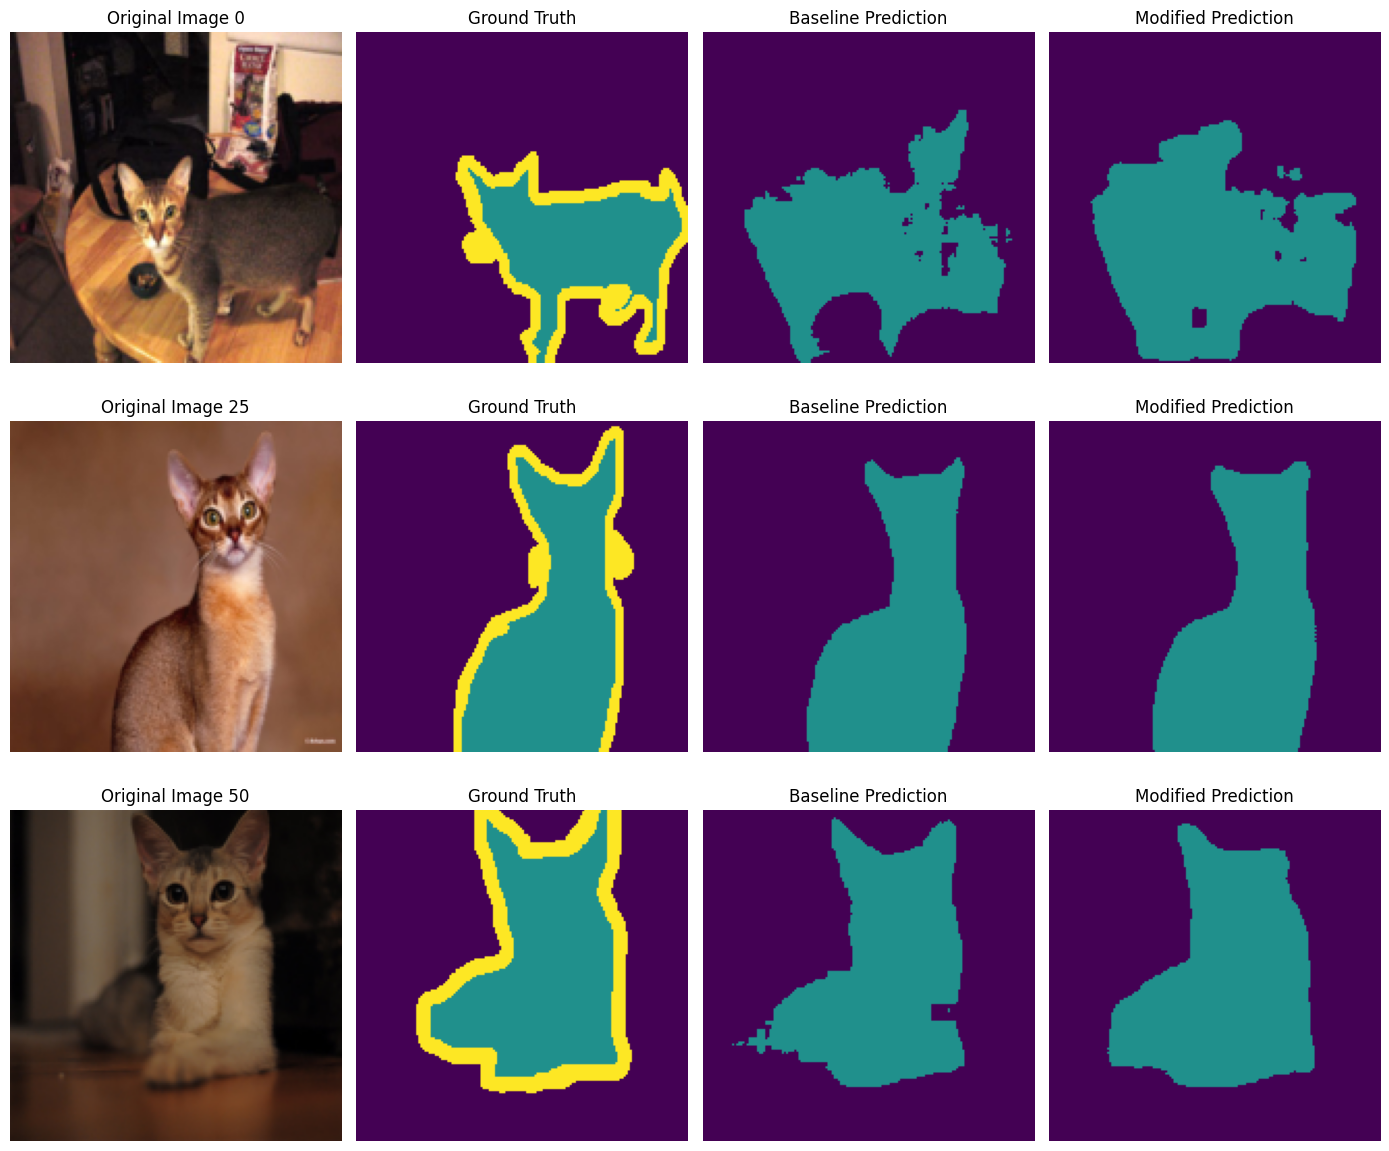

In [ ]:

import matplotlib.pyplot as plt

def visualize_comparison(indices):

    fig, axes = plt.subplots(
        len(indices), 4,
        figsize=(14, 4 * len(indices)),
        squeeze=False
    )

    for row, idx in enumerate(indices):

        image, mask = test_processed[int(idx)]

        input_tensor = image.unsqueeze(0).to(device)

        with torch.inference_mode():

            baseline_pred = baseline_model(
                input_tensor
            ).argmax(dim=1).squeeze().cpu().numpy()

            modified_pred = modified_model(
                input_tensor
            ).argmax(dim=1).squeeze().cpu().numpy()

        image_np = image.permute(1, 2, 0).numpy()

        # Visualization only: ignored pixels become 2
        ground_truth = mask.numpy().copy()
        ground_truth[ground_truth == 255] = 2

        axes[row, 0].imshow(image_np)
        axes[row, 0].set_title(f"Original Image {idx}")

        axes[row, 1].imshow(
            ground_truth,
            cmap="viridis",
            vmin=0,
            vmax=2
        )
        axes[row, 1].set_title("Ground Truth")

        axes[row, 2].imshow(
            baseline_pred,
            cmap="viridis",
            vmin=0,
            vmax=2
        )
        axes[row, 2].set_title("Baseline Prediction")

        axes[row, 3].imshow(
            modified_pred,
            cmap="viridis",
            vmin=0,
            vmax=2
        )
        axes[row, 3].set_title("Modified Prediction")

        for ax in axes[row]:
            ax.axis("off")

    plt.tight_layout()
    plt.savefig(
        "segmentation_comparison.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()


# Visualize three test images
visualize_comparison([0, 25, 50])


Failure Cases

Worst baseline segmentation cases:
Test image 1093: Pet IoU = 0.0000
Test image 1690: Pet IoU = 0.0000
Test image 1858: Pet IoU = 0.0000


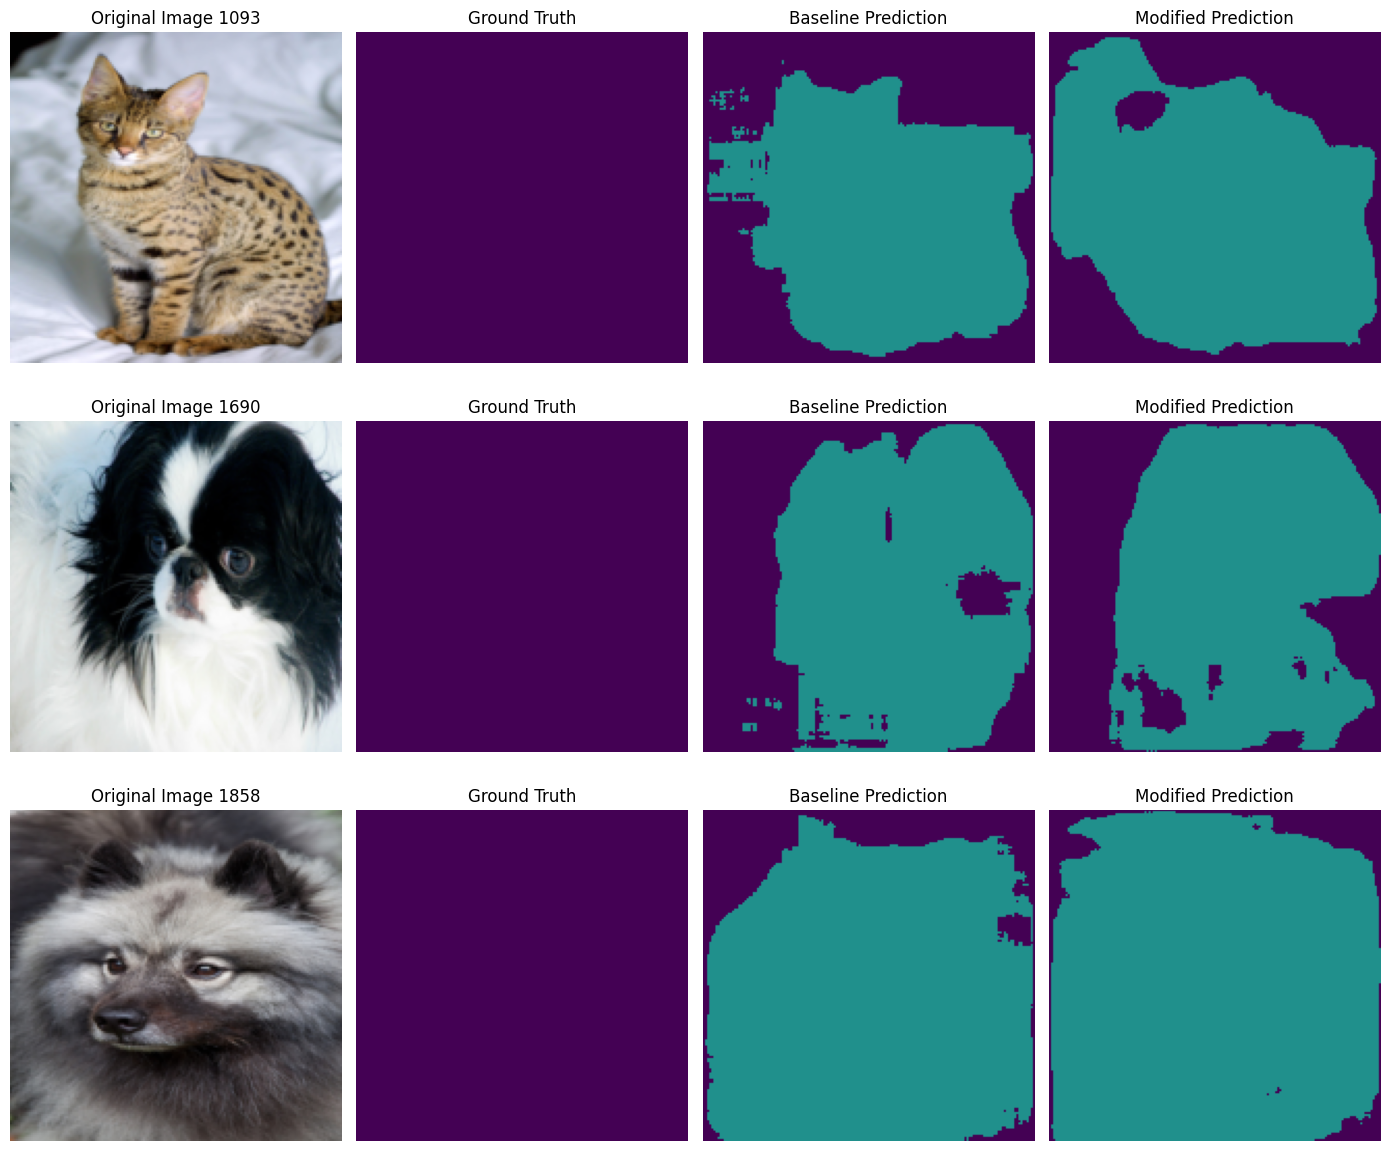

In [ ]:

# Sort individual test images by their pet IoU
worst_cases = sorted(
    baseline_results["per_image_pet_iou"],
    key=lambda x: x[1]
)[:3]

print("Worst baseline segmentation cases:")

for idx, iou in worst_cases:
    print(
        f"Test image {idx}: Pet IoU = {iou:.4f}"
    )

# Compare both models on these difficult images
worst_indices = [idx for idx, _ in worst_cases]

visualize_comparison(worst_indices)


Saving Results

In [ ]:

import json
import torchvision

device_name = (
    torch.cuda.get_device_name(0)
    if device.type == "cuda"
    else "CPU"
)

evaluation_summary = {
    "dataset": "Oxford-IIIT Pet",
    "test_images": len(test_processed),
    "image_resolution": [160, 160],
    "ignored_label": 255,
    "seed": SEED,
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "device": device_name,
    "latency_conditions": {
        "batch_size": 1,
        "warmup_runs": 10,
        "timed_runs": 50,
        "unit": "milliseconds",
        "measurement": "forward pass only"
    },
    "baseline": {
        "background_iou": baseline_results["background_iou"],
        "pet_iou": baseline_results["pet_iou"],
        "miou": baseline_results["miou"],
        "parameters": baseline_params,
        "latency": baseline_latency
    },
    "modified": {
        "background_iou": modified_results["background_iou"],
        "pet_iou": modified_results["pet_iou"],
        "miou": modified_results["miou"],
        "parameters": modified_params,
        "latency": modified_latency
    }
}

with open("evaluation_results.json", "w") as f:
    json.dump(evaluation_summary, f, indent=4)

print("Evaluation results saved successfully!")


Evaluation results saved successfully!


In [ ]:

from google.colab import files

files.download("model_comparison.csv")
files.download("evaluation_results.json")
files.download("segmentation_comparison.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>